# SFT Penilai Kelogisan TOR (format kelompok) — Qwen3-4B-Instruct-2507 — **Google Colab A100**

Notebook ini membaca dataset `kelompok_out` dari **Google Drive**, menjalankan **EDA** (eksplorasi & pengecekan kualitas data), lalu melatih **Qwen3-4B-Instruct-2507 + LoRA** dan mengevaluasinya di test set (**100% TOR asli**).

**Sebelum mulai**
1. *Runtime → Change runtime type → **A100 GPU***.
2. Upload 6 file berikut ke satu folder Drive (default `MyDrive/telaah_kelompok/data/`):
   `train.jsonl`, `val.jsonl`, `test.jsonl`, `train_meta.jsonl`, `val_meta.jsonl`, `test_meta.jsonl`.
3. (opsional) Simpan `HF_TOKEN` di *Secrets* (ikon kunci di panel kiri) agar unduhan model lebih lancar.
4. Jalankan sel dari atas. Bagian 1–3 (EDA) **tidak butuh GPU besar** dan bisa dijalankan dulu untuk memeriksa data.

**Hasil disimpan ke Drive** (`OUT_DIR`): checkpoint, adapter LoRA, prediksi test, dan metrik. Kalau sesi Colab putus, jalankan ulang sel 1–2 lalu sel training — training **dilanjutkan** dari checkpoint terakhir.

## 1. Mount Google Drive, cek GPU & instal library

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!nvidia-smi --query-gpu=name,memory.total --format=csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB


In [ ]:
!pip uninstall -y torchao

In [ ]:
!pip install -q -U "transformers>=4.51" "trl>=0.19" "peft>=0.15" accelerate datasets liger-kernel

In [ ]:
import os
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
import json, gc, math, re, time, inspect, random
from collections import Counter, defaultdict
import torch, transformers, trl, peft
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
print("torch", torch.__version__, "| transformers", transformers.__version__, "| trl", trl.__version__, "| peft", peft.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB",
          "| bf16:", torch.cuda.is_bf16_supported())
else:
    print("PERINGATAN: GPU tidak terdeteksi. EDA tetap bisa jalan, training butuh A100.")
try:
    import liger_kernel  # noqa: F401
    HAS_LIGER = True
except Exception:
    HAS_LIGER = False
print("liger-kernel:", HAS_LIGER)

torch 2.14.1+cu130 | transformers 5.23.0 | trl 1.18.1 | peft 0.21.3
GPU: NVIDIA A100-SXM4-80GB 85 GB | bf16: True
liger-kernel: True


## 2. Konfigurasi
Ubah path & hyperparameter di sini saja.

In [ ]:
DATA_DIR = "/content/drive/MyDrive/dataset_kelompok/data"            # folder berisi 6 file jsonl
OUT_DIR  = "/content/drive/MyDrive/telaah_kelompok/qwen3-4b-kelompok-lora"   # hasil training (di Drive, aman bila sesi putus)
os.makedirs(OUT_DIR, exist_ok=True)

try:                                                   # (opsional) HF token dari Colab Secrets
    from google.colab import userdata
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    print("HF token terpasang")
except Exception as e:
    print("HF token tidak diset (opsional):", str(e)[:80])

MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
MAX_LEN = 6144             # baris terpanjang ~4.600 token; yang melebihi dibuang dari train/val (dilaporkan)
EPOCHS = 3
LR = 2e-4
BATCH = 4                  # A100 40/80 GB
GRAD_ACCUM = 4             # batch efektif 16
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
VAL_SUBSET = 400           # baris val untuk eval_loss selama training (berimbang antar kelompok)
EVAL_EVERY = 50
SEED = 42
MAX_NEW_TOKENS = 768       # jawaban kelompok Latar Belakang/Strategi berisi 3 butir
GEN_BATCH = 16             # batch inferensi evaluasi
USE_LIGER = HAS_LIGER      # bila training error menyebut liger/triton, set False
SIMILAR_THRESHOLD = 0.30   # TOR test yang >=30% isinya sama dengan TOR train ditandai "mirip"

FILES = ("train", "val", "test", "train_meta", "val_meta", "test_meta")
for f in FILES:
    p = f"{DATA_DIR}/{f}.jsonl"
    print(f"{f}.jsonl".ljust(18), "OK" if os.path.exists(p) else "TIDAK ADA -> cek DATA_DIR")

HF token tidak diset (opsional): Secret HF_TOKEN does not exist.
train.jsonl        OK
val.jsonl          OK
test.jsonl         OK
train_meta.jsonl   OK
val_meta.jsonl     OK
test_meta.jsonl    OK


## 3. Muat data
Format *prompt-completion*: `system` (kriteria) + `user` (identitas + isi bagian) → jawaban JSON berkunci kode butir. Satu baris = satu **kelompok** bagian; kelompok Latar Belakang dan Strategi berisi 3 butir (2 anak + 1 induk).

In [ ]:
BUTIR_NAME = {
    "I.M.2": "Dasar Hukum", "I.M.3": "Gambaran Umum", "I.M.1": "Latar Belakang",
    "I.O.2": "Metode Pelaksanaan", "I.O.3": "Tahapan dan Waktu Pelaksanaan",
    "I.O.1": "Strategi Pencapaian Keluaran", "I.N.1": "Penerima Manfaat",
    "I.P": "Kurun Waktu Pencapaian Keluaran", "I.Q": "Biaya yang Diperlukan",
    "I.R": "Manajemen Risiko",
}
BUTIR_ORDER = list(BUTIR_NAME)
SPLITS = ("train", "val", "test")

def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

rows = {s: load_jsonl(f"{DATA_DIR}/{s}.jsonl") for s in SPLITS}
meta = {s: load_jsonl(f"{DATA_DIR}/{s}_meta.jsonl") for s in SPLITS}
for s in SPLITS:
    assert len(rows[s]) == len(meta[s]), f"{s}: jumlah baris data dan meta berbeda"
    for r, m in zip(rows[s], meta[s]):
        r["_meta"] = m
    print(f"{s:5s} {len(rows[s]):5d} baris")

train  3899 baris
val    2615 baris
test    928 baris


## 4. EDA (Exploratory Data Analysis)
### 4.1 Ukuran dataset per split
Jumlah baris, versi dokumen (LOLOS/REVISI), TOR sumber, dan asal TOR.

In [ ]:
ring = []
for s in SPLITS:
    M = meta[s]
    docs = {m["doc_id"]: m["doc_status"] for m in M}
    st = Counter(docs.values())
    ring.append({"split": s, "baris": len(M), "butir_dinilai": sum(len(m["labels"]) for m in M),
                 "versi_TOR": len(docs), "LOLOS": st["LOLOS"], "REVISI": st["REVISI"],
                 "TOR_sumber": len({m["tor_asal"] for m in M}),
                 "TOR_asli": len({m["tor_asal"] for m in M if m["sumber"] == "asli"})})
display(pd.DataFrame(ring))

src = pd.DataFrame([{"split": s, "sumber": m["sumber"]} for s in SPLITS for m in meta[s]])
display(pd.crosstab(src["sumber"], src["split"], margins=True).rename_axis(None, axis=1)
        .style.set_caption("Jumlah baris per sumber TOR"))
grp = pd.DataFrame([{"split": s, "kelompok": m["group"]} for s in SPLITS for m in meta[s]])
display(pd.crosstab(grp["kelompok"], grp["split"], margins=True).rename_axis(None, axis=1)
        .style.set_caption("Jumlah baris per kelompok"))

,split,baris,butir_dinilai,versi_TOR,LOLOS,REVISI,TOR_sumber,TOR_asli
0,train,3899,7523,1955,905,1050,604,101
1,val,2615,4277,446,223,223,109,0
2,test,928,1216,228,57,171,57,57


,test,train,val,All
sumber,,,,
asli,928,518,0,1446
chatgpt,0,46,24,70
gemini,0,1189,718,1907
grok,0,269,396,665
haiku5.5,0,1877,1477,3354
All,928,3899,2615,7442


,test,train,val,All
kelompok,,,,
Biaya yang Diperlukan,216,522,446,1184
Kurun Waktu Pencapaian Keluaran,164,522,446,1132
Latar Belakang,56,910,430,1396
Manajemen Risiko,208,521,446,1175
Penerima Manfaat,196,522,446,1164
Strategi Pencapaian Keluaran,88,902,401,1391
All,928,3899,2615,7442


### 4.2 Distribusi label per butir
Train diseimbangkan per **kelompok** (butir induk I.M.1/I.O.1 dan butir tunggal ~1:1; butir anak ~2,5:1). Val/test berisi **dokumen utuh**, sehingga kelas "tidak logis" jauh lebih sedikit → di evaluasi gunakan *balanced accuracy* dan *recall* tidak logis.

split                               train                       val  \
label                               logis tidak logis % tidak logis   
butir                                                                 
I.M.2 Dasar Hukum                     649         261    28.7   373   
I.M.3 Gambaran Umum                   650         260    28.6   373   
I.M.1 Latar Belakang                  455         455    50.0   330   
I.O.2 Metode Pelaksanaan              641         261    28.9   347   
I.O.3 Tahapan dan Waktu Pelaksanaan   641         261    28.9   345   
I.O.1 Strategi Pencapaian Keluaran    451         451    50.0   299   
I.N.1 Penerima Manfaat                261         261    50.0   389   
I.P Kurun Waktu Pencapaian Keluaran   261         261    50.0   391   
I.Q Biaya yang Diperlukan             261         261    50.0   391   
I.R Manajemen Risiko                  259         262    50.3   389   

split                                                    test              \
label                               tidak logis % tidak logis tidak logis   
butir                                                                       
I.M.2 Dasar Hukum                            57    13.3    29          27   
I.M.3 Gambaran Umum                          57    13.3    29          27   
I.M.1 Latar Belakang                        100    23.3    20          36   
I.O.2 Metode Pelaksanaan                     54    13.5    60          28   
I.O.3 Tahapan dan Waktu Pelaksanaan          56    14.0    60          28   
I.O.1 Strategi Pencapaian Keluaran          102    25.4    41          47   
I.N.1 Penerima Manfaat                       57    12.8   142          54   
I.P Kurun Waktu Pencapaian Keluaran          55    12.3   111          53   
I.Q Biaya yang Diperlukan                    55    12.3   163          53   
I.R Manajemen Risiko                         57    12.8   155          53   

split                                        
label                               % tidak  
butir                                        
I.M.2 Dasar Hukum                      48.2  
I.M.3 Gambaran Umum                    48.2  
I.M.1 Latar Belakang                   64.3  
I.O.2 Metode Pelaksanaan               31.8  
I.O.3 Tahapan dan Waktu Pelaksanaan    31.8  
I.O.1 Strategi Pencapaian Keluaran     53.4  
I.N.1 Penerima Manfaat                 27.6  
I.P Kurun Waktu Pencapaian Keluaran    32.3  
I.Q Biaya yang Diperlukan              24.5  
I.R Manajemen Risiko                   25.5

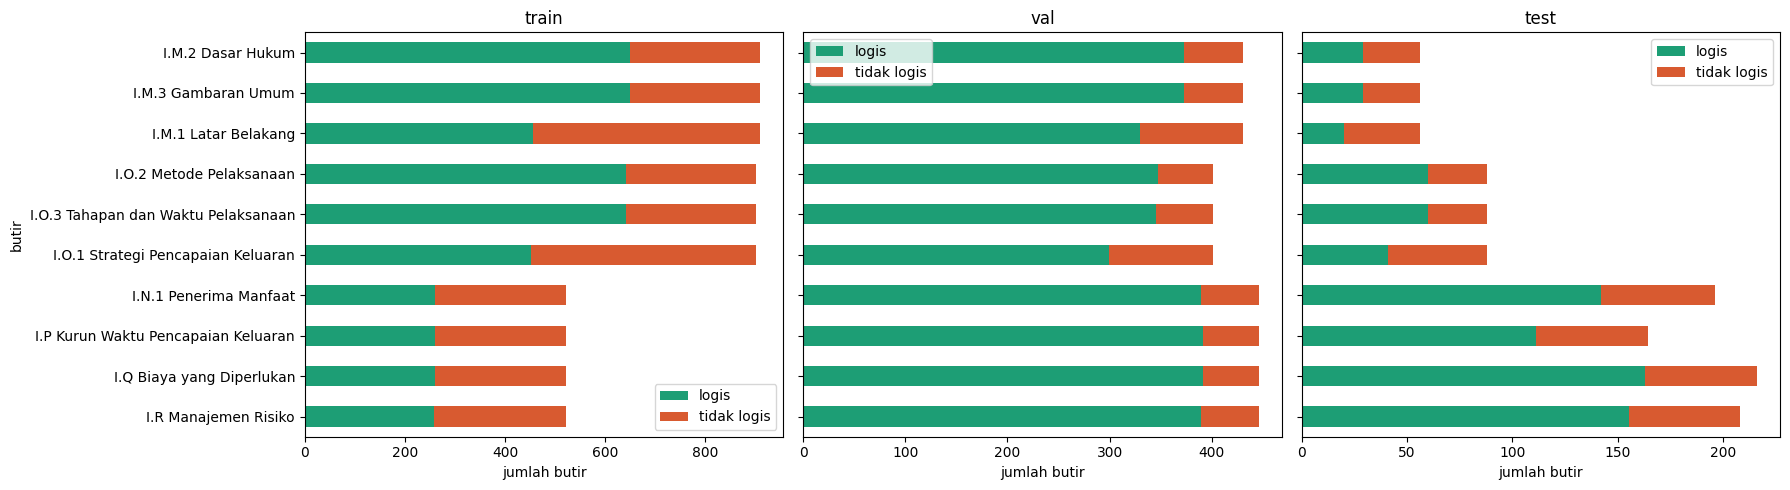

In [ ]:
lab = []
for s in SPLITS:
    for m in meta[s]:
        for c, v in m["labels"].items():
            lab.append({"split": s, "butir": f"{c} {BUTIR_NAME[c]}", "label": "logis" if v else "tidak logis"})
lab = pd.DataFrame(lab)
tab = lab.pivot_table(index="butir", columns=["split", "label"], aggfunc="size", fill_value=0)
tab = tab.reindex([f"{c} {BUTIR_NAME[c]}" for c in BUTIR_ORDER])
for s in SPLITS:
    tab[(s, "% tidak")] = (100 * tab[(s, "tidak logis")] / (tab[(s, "logis")] + tab[(s, "tidak logis")])).round(1)
display(tab[[(s, k) for s in SPLITS for k in ("logis", "tidak logis", "% tidak")]])

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, s in zip(axes, SPLITS):
    t = tab[[(s, "logis"), (s, "tidak logis")]]
    t.columns = ["logis", "tidak logis"]
    t.plot.barh(stacked=True, ax=ax, color=["#1D9E75", "#D85A30"])
    ax.set_title(f"{s}"); ax.set_xlabel("jumlah butir"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

### 4.3 Jenis kerusakan (cara label "tidak logis" dibuat)
Hanya butir berlabel **tidak logis**. `INDUK` = butir induk yang tidak logis karena salah satu anaknya rusak; lainnya = jenis kerusakan sintetis.

In [ ]:
met = pd.DataFrame([{"split": s, "butir": c, "metode": m["metode"][c], "logis": m["labels"][c]}
                    for s in SPLITS for m in meta[s] for c in m["labels"]])
rusak = met[~met["logis"]]                      # hanya butir berlabel tidak logis
display(pd.crosstab(rusak["metode"], rusak["split"], margins=True).sort_values("All", ascending=False)
        .rename_axis(None, axis=1).style.set_caption("Jumlah butir per metode kerusakan"))
display(pd.crosstab([rusak["butir"]], rusak["metode"]).reindex([c for c in BUTIR_ORDER if c in set(rusak["butir"])])
        .style.set_caption("Metode kerusakan x butir (semua split)"))

,test,train,val,All
metode,,,,
All,406,2994,650,4050
INDUK,83,906,202,1191
TUKAR_UNSUR,81,636,147,864
KOSONG,56,383,91,530
SIMBOL,47,319,77,443
HAPUS_SUBBAGIAN,14,175,40,229
HAPUS_NOMINAL,25,127,27,179
HAPUS_WAKTU,34,113,18,165
TUKAR_DOKUMEN,12,124,26,162


metode,HAPUS_METODE,HAPUS_NOMINAL,HAPUS_REGULASI,HAPUS_SUBBAGIAN,HAPUS_VOLUME,HAPUS_WAKTU,INDUK,KOSONG,KOSONG_TABEL,SIMBOL,TUKAR_DOKUMEN,TUKAR_UNSUR
butir,,,,,,,,,,,,
I.M.2,0,0,49,74,0,0,0,64,0,53,0,105
I.M.3,0,0,0,39,106,0,0,34,0,28,81,56
I.M.1,0,0,0,0,0,0,591,0,0,0,0,0
I.O.2,32,0,0,78,0,0,0,68,0,55,0,110
I.O.3,0,0,0,38,0,109,0,33,0,29,81,55
I.O.1,0,0,0,0,0,0,600,0,0,0,0,0
I.N.1,0,0,0,0,0,0,0,109,0,91,0,172
I.P,0,0,0,0,0,56,0,90,0,76,0,147
I.Q,0,179,0,0,0,0,0,54,0,46,0,90


### 4.4 Panjang token (tokenizer Qwen3)
Baris > `MAX_LEN` dibuang dari train/val (tidak dipotong).

,split,median,p95,maks,> MAX_LEN (6144),jawaban median,jawaban maks
0,train,879,1433,5411,0,170,510
1,val,699,1270,1617,0,77,480
2,test,886,2135,4428,0,112,484


/tmp/ipykernel_2136/1564979041.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(list(gl.values()), vert=False, labels=list(gl.keys()))


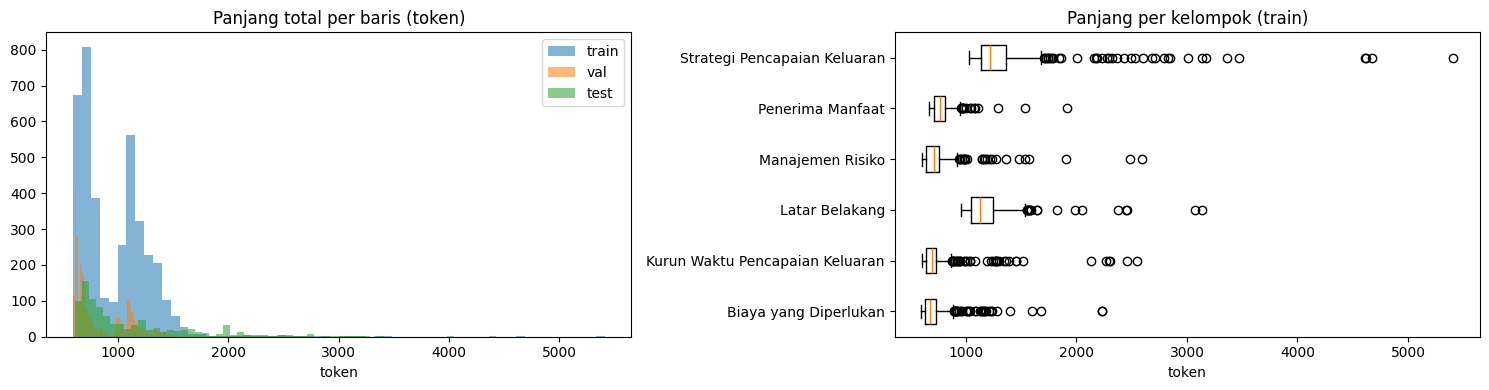

In [ ]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

def n_tokens(msgs):
    return len(tok(tok.apply_chat_template(msgs, tokenize=False), add_special_tokens=False)["input_ids"])

for s in SPLITS:
    for r in rows[s]:
        r["_len"] = n_tokens(r["prompt"] + r["completion"])
        r["_len_out"] = len(tok(r["completion"][0]["content"], add_special_tokens=False)["input_ids"])

stat = []
for s in SPLITS:
    L = pd.Series([r["_len"] for r in rows[s]]); O = pd.Series([r["_len_out"] for r in rows[s]])
    stat.append({"split": s, "median": int(L.median()), "p95": int(L.quantile(.95)), "maks": int(L.max()),
                 f"> MAX_LEN ({MAX_LEN})": int((L > MAX_LEN).sum()),
                 "jawaban median": int(O.median()), "jawaban maks": int(O.max())})
display(pd.DataFrame(stat))
if max(r["_len_out"] for s in SPLITS for r in rows[s]) > MAX_NEW_TOKENS:
    print(f"PERINGATAN: ada jawaban gold > MAX_NEW_TOKENS ({MAX_NEW_TOKENS}); naikkan MAX_NEW_TOKENS")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for s in SPLITS:
    axes[0].hist([r["_len"] for r in rows[s]], bins=60, alpha=.55, label=s)
axes[0].set_title("Panjang total per baris (token)"); axes[0].set_xlabel("token"); axes[0].legend()
gl = defaultdict(list)
for r in rows["train"]:
    gl[r["_meta"]["group"]].append(r["_len"])
axes[1].boxplot(list(gl.values()), vert=False, labels=list(gl.keys()))
axes[1].set_title("Panjang per kelompok (train)"); axes[1].set_xlabel("token")
plt.tight_layout(); plt.show()

### 4.5 Kualitas jawaban (alasan & saran)
Pengecekan otomatis yang harus bernilai **0** (kecuali kutipan, yang wajar < 1%):
- JSON jawaban tidak bisa dibaca / kunci tidak sesuai label,
- butir induk tidak konsisten dengan anaknya (I.M.1 = I.M.2 ∧ I.M.3, I.O.1 = I.O.2 ∧ I.O.3),
- saran tidak konsisten (harus kosong bila logis, terisi bila tidak logis),
- kata yang membocorkan cara data dibuat ("dihapus", "sintetis", "label", ...),
- kutipan dalam `'...'` yang tidak ditemukan di teks bagian.

In [ ]:
BAN = re.compile(r"dihapus|penghapusan|dirusak|sintetis|ditukar|dimanipulasi|\blabel\b|petunjuk|kutipan bukti\s*:", re.I)
QUOTE = re.compile(r"(?<![A-Za-z])'([^']{12,220})'(?![A-Za-z])")
qc, alasan_len = [], []
for s in SPLITS:
    c = Counter()
    for r in rows[s]:
        m = r["_meta"]; u = r["prompt"][1]["content"]
        try:
            a = json.loads(r["completion"][0]["content"])
        except Exception:
            c["json rusak"] += 1; continue
        if list(a) != list(m["labels"]):
            c["kunci tidak sesuai"] += 1
        for k, v in a.items():
            if v.get("logis") != m["labels"].get(k):
                c["logis != label meta"] += 1
            if (not v["logis"]) != bool(v.get("saran", "").strip()):
                c["saran tidak konsisten"] += 1
            if BAN.search(v["alasan"] + v.get("saran", "")):
                c["kata terlarang"] += 1
            for q in QUOTE.findall(v["alasan"]):
                c["kutipan dicek"] += 1
                c["kutipan tidak ditemukan"] += q not in u
            alasan_len.append({"split": s, "butir": k, "logis": v["logis"], "kata_alasan": len(v["alasan"].split()),
                               "kata_saran": len(v.get("saran", "").split())})
        for par, ch in (("I.M.1", ("I.M.2", "I.M.3")), ("I.O.1", ("I.O.2", "I.O.3"))):
            if par in a and a[par]["logis"] != all(a[x]["logis"] for x in ch if x in a):
                c["induk tidak konsisten"] += 1
    qc.append({"split": s, **{k: c[k] for k in ("json rusak", "kunci tidak sesuai", "logis != label meta",
                                                 "induk tidak konsisten", "saran tidak konsisten", "kata terlarang",
                                                 "kutipan tidak ditemukan", "kutipan dicek")}})
display(pd.DataFrame(qc))
al = pd.DataFrame(alasan_len)
display(al.groupby(["split", "logis"])[["kata_alasan", "kata_saran"]].median()
        .style.set_caption("Median jumlah kata alasan & saran"))

,split,json rusak,kunci tidak sesuai,logis != label meta,induk tidak konsisten,saran tidak konsisten,kata terlarang,kutipan tidak ditemukan,kutipan dicek
0,train,0,0,0,0,0,0,12,7385
1,val,0,0,0,0,0,0,0,4297
2,test,0,0,0,0,0,0,6,1505


### 4.6 Cek kebocoran antar split
1. **TOR yang sama** tidak boleh muncul di dua split.
2. **Kemiripan isi**: TOR test dibandingkan dengan semua TOR train memakai potongan 8 kata. TOR test yang ≥ `SIMILAR_THRESHOLD` isinya sama dengan satu TOR train ditandai **mirip** (mis. TOR yang sama beda tahun) dan dievaluasi juga secara terpisah di bagian 7.

In [ ]:
tors = {s: {m["tor_asal"] for m in meta[s]} for s in SPLITS}
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    print(f"TOR sama {a}-{b}: {len(tors[a] & tors[b])}")

def shingles(t, n=8):
    w = t.lower().split()
    return {" ".join(w[i:i + n]) for i in range(len(w) - n + 1)}

def tor_shingles(rs):
    d = defaultdict(set)
    for r in rs:
        d[r["_meta"]["tor_asal"]] |= shingles(r["prompt"][1]["content"].split("\nBagian:", 1)[-1])
    return d

tr_sh, te_sh = tor_shingles(rows["train"]), tor_shingles(rows["test"])
idx = defaultdict(set)
for t, ss in tr_sh.items():
    for g in ss:
        idx[g].add(t)
sim = []
for t, ss in te_sh.items():
    if len(ss) < 30:
        continue
    hit = Counter(u for g in ss for u in idx.get(g, ()))
    if hit:
        u, c = hit.most_common(1)[0]
        sim.append({"tor_test": t, "tor_train_termirip": u, "kemiripan": round(c / len(ss), 2)})
sim = pd.DataFrame(sim).sort_values("kemiripan", ascending=False)
MIRIP_TOR = set(sim.loc[sim["kemiripan"] >= SIMILAR_THRESHOLD, "tor_test"])
print(f"TOR test yang mirip (>= {SIMILAR_THRESHOLD:.0%}) dengan TOR train: {len(MIRIP_TOR)} dari {len(te_sh)}")
display(sim.head(10))

TOR sama train-val: 0
TOR sama train-test: 0
TOR sama val-test: 0
TOR test yang mirip (>= 30%) dengan TOR train: 2 dari 57


,tor_test,tor_train_termirip,kemiripan
3,059.GH.4523.PDI.001 [REV] 1. TOR Fasilitasi UKW-Ranwal 2026,059.GH.4523.SCA.001 9. TOR Pelatihan Jurnalis-Ranwal 2026,0.45
30,059.WA.4513.EBA.969 TOR 2026 - Layanan Bantuan Hukum,2027 - TOR Layanan Bantuan Hukum,0.44
13,TOR Fasilitasi UKW-FE 2027,059.GH.4523.SCA.001 9. TOR Pelatihan Jurnalis-Ranwal 2026,0.26
52,059.WA.7430.EBA.994 TOR Layanan Perkantoran 2026_06062025.docx,059.WA.7430.EBA.956 TOR BMN TA 2026.docx,0.24
7,059.WA.4491.EBD.955 10. TOR Layanan Manajemen Keuangan_TA 2026,059.WA.4491.EBA.960 02. TOR Layanan Organisasi dan Tata Kelola Internal_TA 2026,0.21
10,TOR Perencanaan dan Penganggaran 2027,TOR Layanan Sarana dan Prasarana Internal 2027,0.17
8,TOR Layanan Pengembangan Pers Set DP-FE 2027,TOR Layanan Pengaduan atas Kasus Pers-FE 2027,0.14
9,059.WA.4491.EBA.962 03. TOR Layanan Umum_TA 2026,059.WA.4491.EBA.960 02. TOR Layanan Organisasi dan Tata Kelola Internal_TA 2026,0.13
45,059.WA.4492.EBD.007 5. TOR Layanan Perencanaan dan Penganggaran-Ranwal 2026,059.GH.4523.SCA.001 9. TOR Pelatihan Jurnalis-Ranwal 2026,0.12
41,059.WA.4491.EBA.963 04. TOR Layanan Data dan Informasi_TA 2026,059.WA.4491.EBA.960 02. TOR Layanan Organisasi dan Tata Kelola Internal_TA 2026,0.11


### 4.7 Contoh data
Satu contoh LOLOS dan satu contoh REVISI dari train.

In [ ]:
def show(r, n_user=1200):
    m = r["_meta"]
    print(f"[{m['group']}] {m['tor_asal'][:70]} | status dokumen {m['doc_status']} | metode {m['metode']}")
    print("-" * 100); print(r["prompt"][1]["content"][:n_user])
    print("-" * 100); print(json.dumps(json.loads(r["completion"][0]["content"]), ensure_ascii=False, indent=1))
    print("=" * 100)

rng = random.Random(SEED)
show(rng.choice([r for r in rows["train"] if r["_meta"]["group"] == "Latar Belakang" and all(r["_meta"]["labels"].values())]))
show(rng.choice([r for r in rows["train"] if r["_meta"]["group"] == "Strategi Pencapaian Keluaran" and not all(r["_meta"]["labels"].values())]))
print("System prompt (Strategi):\n", next(r for r in rows["train"] if r["_meta"]["group"] == "Strategi Pencapaian Keluaran")["prompt"][0]["content"])

[Latar Belakang] haiku5.5:Penyusunan Standar Platform Perdagangan Elektronik Daerah | status dokumen LOLOS | metode {'I.M.2': 'ASLI', 'I.M.3': 'ASLI', 'I.M.1': 'INDUK'}
----------------------------------------------------------------------------------------------------
Kegiatan: Penyusunan Standar Platform Perdagangan Elektronik Daerah
Rincian Output: Standar platform perdagangan elektronik tersusun
Volume Rincian Output: 1 standar

Butir dinilai: I.M.2 Dasar Hukum, I.M.3 Gambaran Umum, I.M.1 Latar Belakang

Bagian: Latar Belakang
1. Dasar Hukum
Penyusunan standar platform perdagangan elektronik merupakan tugas fungsi direktorat berdasarkan Undang-Undang Nomor 7 Tahun 2014 tentang Perdagangan.

2. Gambaran Umum
Rincian Output berupa standar platform perdagangan elektronik daerah tersusun untuk pasar lokal dan pelaku usaha kecil. Volume 1 standar ditetapkan sebagai satu standar teknis yang berlaku bagi platform daerah sasaran.
------------------------------------------------------------

## 5. Siapkan dataset training

In [ ]:
from datasets import Dataset

for s in ("train", "val"):
    n0 = len(rows[s])
    rows[s] = [r for r in rows[s] if r["_len"] <= MAX_LEN]
    if len(rows[s]) < n0:
        print(f"PERINGATAN: {n0 - len(rows[s])} baris {s} > MAX_LEN dibuang")

def to_ds(rs):
    return Dataset.from_list([{"prompt": r["prompt"], "completion": r["completion"]} for r in rs])

by = defaultdict(list)
for r in rows["val"]:
    by[r["_meta"]["group"]].append(r)
per = max(1, VAL_SUBSET // len(by))
rng = random.Random(SEED)
val_small = [x for k in sorted(by) for x in rng.sample(by[k], min(per, len(by[k])))]
train_ds, val_ds = to_ds(rows["train"]), to_ds(val_small)
print(f"train {len(train_ds)} baris | val (eval_loss selama training) {len(val_ds)} baris")

train 3899 baris | val (eval_loss selama training) 396 baris


## 6. Model, LoRA & trainer (bf16, A100)

In [ ]:
from transformers import AutoModelForCausalLM, TrainerCallback
from peft import LoraConfig, PeftModel
from trl import SFTConfig, SFTTrainer

def load_base():
    kw = dict(attn_implementation="sdpa", device_map={"": 0})
    try:
        m = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.bfloat16, **kw)
    except TypeError:
        m = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.bfloat16, **kw)
    m.config.use_cache = False
    return m

lora_cfg = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                      target_modules="all-linear", task_type="CAUSAL_LM", bias="none")

STEPS_PER_EPOCH = math.ceil(len(train_ds) / (BATCH * GRAD_ACCUM))
TOTAL_STEPS = STEPS_PER_EPOCH * EPOCHS
print("langkah per epoch:", STEPS_PER_EPOCH, "| total:", TOTAL_STEPS)

def make_config(**over):
    want = dict(
        output_dir=OUT_DIR, num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
        gradient_accumulation_steps=GRAD_ACCUM, learning_rate=LR,
        lr_scheduler_type="cosine", warmup_ratio=0.05, weight_decay=0.0,
        bf16=True, fp16=False,
        gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        logging_steps=10, eval_strategy="steps", eval_steps=EVAL_EVERY,
        save_strategy="steps", save_steps=EVAL_EVERY, save_total_limit=2,
        load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
        report_to="none", seed=SEED, completion_only_loss=True, packing=False,
        use_liger_kernel=USE_LIGER, dataset_num_proc=2,
    )
    want.update(over)
    params = set(inspect.signature(SFTConfig.__init__).parameters)
    want["max_length" if "max_length" in params else "max_seq_length"] = MAX_LEN
    if "warmup_ratio" not in params:
        steps = want["max_steps"] if want.get("max_steps", -1) > 0 else TOTAL_STEPS
        want["warmup_steps"] = max(1, round(0.05 * steps)); want.pop("warmup_ratio", None)
    if "eval_strategy" not in params and "evaluation_strategy" in params:
        want["evaluation_strategy"] = want.pop("eval_strategy")
    dropped = [k for k in want if k not in params]
    if dropped:
        print("parameter tidak didukung versi ini (diabaikan):", dropped)
    return SFTConfig(**{k: v for k, v in want.items() if k in params})

class MemCallback(TrainerCallback):
    def on_step_end(self, args, state, control, **kw):
        if state.global_step in (1, 5) or state.global_step % 50 == 0:
            print(f"[step {state.global_step}/{state.max_steps}] puncak memori GPU {torch.cuda.max_memory_allocated()/1e9:.1f} GB")

def make_trainer(model, cfg, train, val=None):
    kw = dict(model=model, args=cfg, train_dataset=train, eval_dataset=val, peft_config=lora_cfg, callbacks=[MemCallback()])
    sig = set(inspect.signature(SFTTrainer.__init__).parameters)
    kw["processing_class" if "processing_class" in sig else "tokenizer"] = tok
    return SFTTrainer(**kw)

langkah per epoch: 244 | total: 732


### 6.1 Smoke test (wajib sekali)
Melatih 3 langkah dengan baris **terpanjang**. Kalau lolos tanpa *out of memory*, training penuh pasti muat. Sel ini juga memperkirakan lama training.
Kalau OOM: set `BATCH = 2`, `GRAD_ACCUM = 8` di bagian 2, lalu jalankan ulang dari bagian 2.

In [ ]:
torch.cuda.reset_peak_memory_stats()
model = load_base()
longest = sorted(rows["train"], key=lambda r: -r["_len"])[: BATCH * 3]
smoke_cfg = make_config(output_dir="/content/smoke", max_steps=3, gradient_accumulation_steps=1,
                        eval_strategy="no", save_strategy="no", load_best_model_at_end=False, logging_steps=1)
smoke = make_trainer(model, smoke_cfg, to_ds(longest))
t0 = time.time(); smoke.train(); dt = (time.time() - t0) / 3
mean_len = sum(r["_len"] for r in rows["train"]) / len(rows["train"])
est = dt * (mean_len / longest[0]["_len"]) * GRAD_ACCUM * TOTAL_STEPS / 60
print(f"SMOKE TEST OK - puncak memori {torch.cuda.max_memory_allocated()/1e9:.1f} GB, {dt:.1f} detik/langkah (baris ~{longest[0]['_len']} token)")
print(f"Perkiraan kasar training penuh: ~{est:.0f} menit (+ eval berkala)")
b = smoke.train_dataset[0]
if "completion_mask" in b:
    print("token yang dihitung loss:", sum(b["completion_mask"]), "dari", len(b["input_ids"]))
del smoke, model; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing_kwargs` is deprecated and will be removed in v6. Use `activation_checkpointing_kwargs` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Tokenizing train dataset (num_proc=2):   0%|          | 0/12 [00:00<?, ? examples/s]

Building labels for train dataset (num_proc=2):   0%|          | 0/12 [00:00<?, ? examples/s]

Truncating train dataset (num_proc=2):   0%|          | 0/12 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset (num_proc=2):   0%|          | 0/12 [00:00<?, ? examples/s]

/tmp/ipykernel_2136/910003722.py:57: FutureWarning: `use_liger_kernel=True` is deprecated and will be removed in v2.0.0. Use the Hub kernels instead, with `model_init_kwargs={"use_kernels": True}`.
  return SFTTrainer(**kw)


[step 1/3] puncak memori GPU 17.3 GB


Step,Training Loss
1,1.592314
2,1.572097
3,1.073581


SMOKE TEST OK - puncak memori 19.0 GB, 11.0 detik/langkah (baris ~5411 token)
Perkiraan kasar training penuh: ~96 menit (+ eval berkala)


### 6.2 Training penuh
Checkpoint disimpan ke Drive tiap `EVAL_EVERY` langkah. Bila sesi putus: jalankan sel bagian 1–3, 4.4, 5, 6, lalu sel ini → training dilanjutkan.

In [ ]:
torch.cuda.reset_peak_memory_stats()
model = load_base()
trainer = make_trainer(model, make_config(), train_ds, val_ds)
has_ckpt = any(d.startswith("checkpoint-") for d in os.listdir(OUT_DIR))
t0 = time.time()
trainer.train(resume_from_checkpoint=True if has_ckpt else None)
print(f"selesai dalam {(time.time()-t0)/60:.0f} menit; puncak memori {torch.cuda.max_memory_allocated()/1e9:.1f} GB")

ADAPTER_DIR = f"{OUT_DIR}/final_adapter"
trainer.model.save_pretrained(ADAPTER_DIR); tok.save_pretrained(ADAPTER_DIR)
print("adapter (checkpoint terbaik menurut eval_loss) disimpan ke", ADAPTER_DIR)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing_kwargs` is deprecated and will be removed in v6. Use `activation_checkpointing_kwargs` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Tokenizing train dataset (num_proc=2):   0%|          | 0/3899 [00:00<?, ? examples/s]

Building labels for train dataset (num_proc=2):   0%|          | 0/3899 [00:00<?, ? examples/s]

Truncating train dataset (num_proc=2):   0%|          | 0/3899 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset (num_proc=2):   0%|          | 0/3899 [00:00<?, ? examples/s…

... (5 outputs left out)

[step 1/732] puncak memori GPU 10.8 GB


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,0.396211,0.296447,0.291285,0.915588,783515.000000
100,0.300807,0.215199,0.229007,0.934680,1541463.000000
150,0.272434,0.189871,0.213205,0.940316,2319052.000000
200,0.262068,0.172441,0.184585,0.944758,3094912.000000
250,0.230424,0.158424,0.144404,0.948761,3873680.000000
300,0.215006,0.150883,0.148293,0.950541,4650447.000000
350,0.199020,0.147299,0.133846,0.952462,5425433.000000
400,0.195913,0.138914,0.136401,0.953202,6204496.000000
450,0.200430,0.132599,0.131988,0.956977,6980363.000000
500,0.158486,0.127926,0.107007,0.959113,7751488.000000


[step 5/732] puncak memori GPU 11.6 GB
[step 50/732] puncak memori GPU 17.5 GB


[step 100/732] puncak memori GPU 17.5 GB
[step 150/732] puncak memori GPU 19.1 GB
[step 200/732] puncak memori GPU 19.1 GB
[step 250/732] puncak memori GPU 19.1 GB
[step 300/732] puncak memori GPU 19.1 GB
[step 350/732] puncak memori GPU 19.1 GB
[step 400/732] puncak memori GPU 19.1 GB
[step 450/732] puncak memori GPU 19.1 GB
[step 500/732] puncak memori GPU 19.1 GB
[step 550/732] puncak memori GPU 19.1 GB
[step 600/732] puncak memori GPU 19.1 GB
[step 650/732] puncak memori GPU 19.1 GB
[step 700/732] puncak memori GPU 19.1 GB
selesai dalam 72 menit; puncak memori 19.1 GB
adapter (checkpoint terbaik menurut eval_loss) disimpan ke /content/drive/MyDrive/telaah_kelompok/qwen3-4b-kelompok-lora/final_adapter


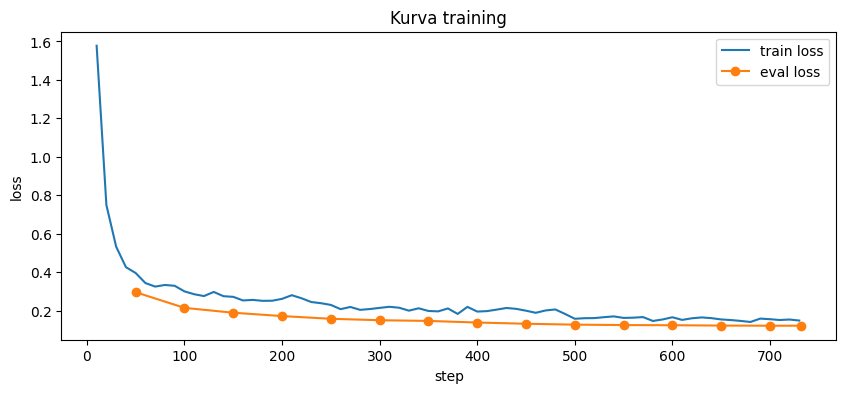

In [ ]:
hist = pd.DataFrame(trainer.state.log_history)
hist.to_csv(f"{OUT_DIR}/log_history.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4))
if "loss" in hist: ax.plot(hist.dropna(subset=["loss"])["step"], hist.dropna(subset=["loss"])["loss"], label="train loss")
if "eval_loss" in hist: ax.plot(hist.dropna(subset=["eval_loss"])["step"], hist.dropna(subset=["eval_loss"])["eval_loss"], "o-", label="eval loss")
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.legend(); ax.set_title("Kurva training"); plt.show()

## 7. Evaluasi di test set (100% TOR asli)
Inferensi greedy. Metrik:
- **per butir**: akurasi, *balanced accuracy*, precision/recall/F1 kelas **tidak logis**,
- **per metode kerusakan**,
- **per dokumen**: TOR = REVISI bila ≥1 butir diprediksi tidak logis. Test berisi 57 LOLOS / 171 REVISI, jadi lihat **balanced accuracy** dan baris "gold LOLOS/REVISI" secara terpisah,
- versi **tanpa TOR mirip** (bagian 4.6) untuk memastikan hasil tidak terdongkrak kemiripan dengan train.

Set `EVAL_BASELINE=True` untuk membandingkan dengan model dasar tanpa fine-tune.

In [ ]:
EVAL_BASELINE = False

def parse_output(txt):
    t = re.sub(r"^```(?:json)?|```$", "", txt.strip(), flags=re.M).strip()
    for cand in (t, (re.search(r"\{.*\}", t, re.S) or [None])[0]):
        if cand:
            try:
                j = json.loads(cand)
                if isinstance(j, dict):
                    return j
            except Exception:
                pass
    return None

def get_logis(pred_j, code):
    v = pred_j.get(code) if isinstance(pred_j, dict) else None
    return v["logis"] if isinstance(v, dict) and isinstance(v.get("logis"), bool) else None

@torch.no_grad()
def predict(model, rs, label="", bs=GEN_BATCH):
    model.eval(); model.config.use_cache = True
    try: model.gradient_checkpointing_disable()
    except Exception: pass
    tok.padding_side = "left"
    order = sorted(range(len(rs)), key=lambda i: -rs[i]["_len"])
    out = [None] * len(rs); t0 = time.time()
    for k in range(0, len(order), bs):
        idx = order[k:k + bs]
        texts = [tok.apply_chat_template(rs[i]["prompt"], tokenize=False, add_generation_prompt=True) for i in idx]
        enc = tok(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=tok.pad_token_id)
        for j, i in enumerate(idx):
            txt = tok.decode(gen[j, enc["input_ids"].shape[1]:], skip_special_tokens=True)
            out[i] = {"raw": txt, "pred": parse_output(txt)}
        done = k + len(idx)
        if (k // bs) % 10 == 0 or done == len(rs):
            el = time.time() - t0
            print(f"{label} {done}/{len(rs)}  {el/60:.1f} menit, sisa ~{el/done*(len(rs)-done)/60:.1f} menit")
    tok.padding_side = "right"
    return out

def prf(tp, fp, fn, tn):
    p = tp / (tp + fp) if tp + fp else float("nan")
    r = tp / (tp + fn) if tp + fn else float("nan")
    f = 2 * p * r / (p + r) if p == p and r == r and p + r else float("nan")
    spec = tn / (tn + fp) if tn + fp else float("nan")
    return p, r, f, spec

def evaluate(rs, preds, name, show=True):
    bad_rows = sum(p["pred"] is None for p in preds); missing = total = 0
    per = defaultdict(Counter); meth = defaultdict(Counter); docs = defaultdict(lambda: [None, False])
    for r, pdct in zip(rs, preds):
        m = r["_meta"]; d = docs[m["doc_id"]]; d[0] = m["doc_status"]
        for code, gold in m["labels"].items():
            total += 1
            pl = get_logis(pdct["pred"], code)
            if pl is None:
                pl = True; missing += 1        # tak terbaca -> dianggap logis (terburuk untuk recall)
            gneg, pneg = (not gold), (not pl)
            key = "tp" if gneg and pneg else "fn" if gneg else "fp" if pneg else "tn"
            per[code][key] += 1; per["SEMUA"][key] += 1
            meth[m["metode"][code]]["benar" if pl == gold else "salah"] += 1
            d[1] = d[1] or pneg
    tab = []
    for code in BUTIR_ORDER + ["SEMUA"]:
        c = per[code]; n = sum(c.values())
        if not n: continue
        p, r, f, spec = prf(c["tp"], c["fp"], c["fn"], c["tn"])
        tab.append({"butir": code if code == "SEMUA" else f"{code} {BUTIR_NAME[code]}", "n": n,
                    "tidak_logis_gold": c["tp"] + c["fn"], "akurasi": (c["tp"] + c["tn"]) / n,
                    "balanced_acc": (r + spec) / 2, "precision_TIDAK": p, "recall_TIDAK": r, "F1_TIDAK": f})
    df = pd.DataFrame(tab)
    dm = pd.DataFrame([{"metode": k, "n": sum(v.values()), "benar": v["benar"] / sum(v.values())} for k, v in sorted(meth.items())])
    dc = Counter((st, "REVISI" if prev else "LOLOS") for st, prev in docs.values())
    tp, fp, fn, tn = dc[("REVISI", "REVISI")], dc[("LOLOS", "REVISI")], dc[("REVISI", "LOLOS")], dc[("LOLOS", "LOLOS")]
    p, r, f, spec = prf(tp, fp, fn, tn)
    doc = {"model": name, "dokumen": len(docs), "akurasi": (tp + tn) / len(docs), "balanced_acc": (r + spec) / 2,
           "LOLOS_benar": f"{tn}/{tn+fp}", "REVISI_benar": f"{tp}/{tp+fn}", "precision_REVISI": p, "recall_REVISI": r}
    if show:
        print(f"\n===== {name} =====")
        print(f"Baris tak terparse: {bad_rows}/{len(rs)} | butir tak terbaca: {missing}/{total}")
        print(f"TINGKAT DOKUMEN ({len(docs)} TOR): akurasi {doc['akurasi']:.1%} | balanced acc {doc['balanced_acc']:.1%} | "
              f"precision REVISI {p:.1%} | recall REVISI {r:.1%}")
        print(f"   gold LOLOS  -> pred LOLOS {tn}, pred REVISI {fp}")
        print(f"   gold REVISI -> pred REVISI {tp}, pred LOLOS {fn}")
        print("\nPER BUTIR (positif = TIDAK logis):"); display(df.round(3))
        print("PER METODE:"); display(dm.round(3))
    return df, dm, doc

test_rows = rows["test"]

In [ ]:
try:
    model = trainer.model
except NameError:                                   # sesi baru: muat adapter dari Drive
    model = PeftModel.from_pretrained(load_base(), f"{OUT_DIR}/final_adapter")
try:
    model = model.merge_and_unload()                # gabung LoRA -> inferensi lebih cepat
except Exception as e:
    print("merge dilewati:", e)
preds_ft = predict(model, test_rows, "FT")
df_ft, dm_ft, doc_ft = evaluate(test_rows, preds_ft, "Qwen3-4B + LoRA (fine-tune)")

keep = [i for i, r in enumerate(test_rows) if r["_meta"]["tor_asal"] not in MIRIP_TOR]
_, _, doc_ft_nomirip = evaluate([test_rows[i] for i in keep], [preds_ft[i] for i in keep],
                                f"FT tanpa {len(MIRIP_TOR)} TOR mirip", show=False)
display(pd.DataFrame([doc_ft, doc_ft_nomirip]).round(3))

with open(f"{OUT_DIR}/test_predictions.jsonl", "w", encoding="utf-8") as f:
    for r, p in zip(test_rows, preds_ft):
        pp = {code: get_logis(p["pred"], code) for code in r["_meta"]["labels"]}
        f.write(json.dumps({**r["_meta"], "pred_logis": pp, "raw": p["raw"]}, ensure_ascii=False) + "\n")
df_ft.to_csv(f"{OUT_DIR}/test_metrics_per_butir.csv", index=False)
dm_ft.to_csv(f"{OUT_DIR}/test_metrics_per_metode.csv", index=False)
pd.DataFrame([doc_ft, doc_ft_nomirip]).to_csv(f"{OUT_DIR}/test_metrics_dokumen.csv", index=False)
print("prediksi & metrik disimpan ke", OUT_DIR)

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3280: FutureWarning: `gradient_checkpointing_disable` is deprecated and will be removed in v6. Use `activation_checkpointing_disable` instead.
  warnings.warn(


FT 16/928  0.6 menit, sisa ~33.2 menit
FT 176/928  6.2 menit, sisa ~26.6 menit
FT 336/928  11.0 menit, sisa ~19.3 menit
FT 496/928  13.6 menit, sisa ~11.9 menit
FT 656/928  15.9 menit, sisa ~6.6 menit
FT 816/928  18.1 menit, sisa ~2.5 menit
FT 928/928  19.3 menit, sisa ~0.0 menit

===== Qwen3-4B + LoRA (fine-tune) =====
Baris tak terparse: 0/928 | butir tak terbaca: 0/1216
TINGKAT DOKUMEN (228 TOR): akurasi 96.5% | balanced acc 95.3% | precision REVISI 97.7% | recall REVISI 97.7%
   gold LOLOS  -> pred LOLOS 53, pred REVISI 4
   gold REVISI -> pred REVISI 167, pred LOLOS 4

PER BUTIR (positif = TIDAK logis):


,butir,n,tidak_logis_gold,akurasi,balanced_acc,precision_TIDAK,recall_TIDAK,F1_TIDAK
0,I.M.2 Dasar Hukum,56,27,1.000,1.000,1.000,1.000,1.000
1,I.M.3 Gambaran Umum,56,27,0.857,0.852,1.000,0.704,0.826
2,I.M.1 Latar Belakang,56,36,0.946,0.958,1.000,0.917,0.957
3,I.O.2 Metode Pelaksanaan,88,28,0.955,0.948,0.929,0.929,0.929
4,I.O.3 Tahapan dan Waktu Pelaksanaan,88,28,0.977,0.983,0.933,1.000,0.966
5,I.O.1 Strategi Pencapaian Keluaran,88,47,0.955,0.954,0.957,0.957,0.957
6,I.N.1 Penerima Manfaat,196,54,1.000,1.000,1.000,1.000,1.000
7,I.P Kurun Waktu Pencapaian Keluaran,164,53,0.994,0.995,0.981,1.000,0.991
8,I.Q Biaya yang Diperlukan,216,53,0.995,0.997,0.981,1.000,0.991
9,I.R Manajemen Risiko,208,53,0.990,0.981,1.000,0.962,0.981


PER METODE:


,metode,n,benar
0,ASLI,749,0.992
1,HAPUS_METODE,11,0.909
2,HAPUS_NOMINAL,25,1.000
3,HAPUS_REGULASI,10,1.000
4,HAPUS_SUBBAGIAN,14,0.929
5,HAPUS_VOLUME,8,0.250
6,HAPUS_WAKTU,34,1.000
7,INDUK,144,0.951
8,KOSONG,56,1.000
9,KOSONG_TABEL,25,0.920


,model,dokumen,akurasi,balanced_acc,LOLOS_benar,REVISI_benar,precision_REVISI,recall_REVISI
0,Qwen3-4B + LoRA (fine-tune),228,0.965,0.953,53/57,167/171,0.977,0.977
1,FT tanpa 2 TOR mirip,220,0.964,0.952,51/55,161/165,0.976,0.976


prediksi & metrik disimpan ke /content/drive/MyDrive/telaah_kelompok/qwen3-4b-kelompok-lora


In [ ]:
# Contoh kesalahan (untuk analisis): maks 4 per arah
shown = Counter()
for r, p in zip(test_rows, preds_ft):
    m = r["_meta"]
    for code, gold in m["labels"].items():
        pl = get_logis(p["pred"], code)
        pl = True if pl is None else pl
        if pl != gold and shown[gold] < 4:
            shown[gold] += 1
            print("=" * 100)
            print(f"{code} {BUTIR_NAME[code]} | gold logis={gold} ({m['metode'][code]}) | prediksi logis={pl} | {m['tor_asal'][:70]}")
            print("ISI:", r["prompt"][1]["content"].split("\nBagian:", 1)[-1][:700])
            print("JAWABAN MODEL:", p["raw"][:600])

I.M.3 Gambaran Umum | gold logis=False (TUKAR_DOKUMEN) | prediksi logis=True | 05. TOR Layanan Perkantoran_TA 2027
ISI:  Latar Belakang
1. Dasar Hukum
Dasar hukum kegiatan ini adalah:
a. UU No.17 Tahun 2003 tentang Keuangan Negara, Pasal 3 Ayat (1) bahwa Keuangan Negara dikelola secara tertib, taat pada peraturan perundang-undangan, efisien, ekonomis, efektif, transparan, dan bertanggung jawab dengan memperhatikan rasa keadilan dan kepatutan.
b. Undang-Undang Nomor 1 Tahun 2004 Tentang Perbendaharaan Negara c. PP No.60 Tahun 2008 tentang Sistem Pengendalian Intern Pemerintah d. PP No.10 Tahun 2010 tentang Penyusunan Rencana Kerja Anggaran Kementerian Lembaga e. Peraturan Presiden Nomor 174 Tahun 2024 tentang Kementerian Komunikasi dan Digital f. PM Keuangan No. 32 Tahun 2025 Tentang Standar Biaya Masukan Tahu
JAWABAN MODEL: {"I.M.2": {"logis": true, "alasan": "Bagian ini menyebut 'Dasar hukum kegiatan ini adalah:' dan merujuk pada peraturan perundang-undangan yang berkaitan dengan peng

In [ ]:
# (opsional) pembanding: model dasar tanpa fine-tune
if EVAL_BASELINE:
    del model; gc.collect(); torch.cuda.empty_cache()
    base = load_base()
    preds_base = predict(base, test_rows, "BASE")
    df_base, dm_base, doc_base = evaluate(test_rows, preds_base, "Qwen3-4B-Instruct-2507 (tanpa fine-tune)")
    df_base.to_csv(f"{OUT_DIR}/test_metrics_per_butir_BASELINE.csv", index=False)
    display(pd.DataFrame([doc_base, doc_ft]).round(3))
    del base; gc.collect(); torch.cuda.empty_cache()

## 8. (Opsional) Kualitas alasan — perplexity & BERTScore
- **Perplexity** alasan gold di bawah model fine-tune (forward pass saja, loss hanya di jawaban).
- **BERTScore** antara alasan buatan model dan alasan gold, dipecah prediksi benar vs salah. Catatan: BERTScore mBERT tanpa *rescale* cenderung tinggi untuk teks apa pun yang sebahasa, jadi bandingkan antar kelompok, bukan dibaca sebagai angka mutlak.

In [ ]:
RUN_PPL = True
@torch.no_grad()
def completion_perplexity(model, rs):
    model.eval(); model.config.use_cache = False
    agg = defaultdict(lambda: [0.0, 0])
    for n, r in enumerate(rs, 1):
        full = tok.apply_chat_template(r["prompt"] + r["completion"], tokenize=False)
        prompt_only = tok.apply_chat_template(r["prompt"], tokenize=False, add_generation_prompt=True)
        enc = tok(full, return_tensors="pt", add_special_tokens=False).to(model.device)
        labels = enc["input_ids"].clone(); labels[:, :len(tok(prompt_only, add_special_tokens=False)["input_ids"])] = -100
        k = int((labels != -100).sum())
        if not k: continue
        nll = model(**enc, labels=labels).loss.item() * k
        for key in ("SEMUA", r["_meta"]["group"], "doc_status=" + r["_meta"]["doc_status"]):
            agg[key][0] += nll; agg[key][1] += k
        if n % 100 == 0 or n == len(rs): print(f"perplexity {n}/{len(rs)}")
    model.config.use_cache = True
    return pd.DataFrame([{"kelompok": k, "n_token": t, "perplexity": math.exp(s / t)} for k, (s, t) in agg.items()])
if RUN_PPL:
    df_ppl = completion_perplexity(model, test_rows)
    display(df_ppl.round(3)); df_ppl.to_csv(f"{OUT_DIR}/test_perplexity.csv", index=False)

perplexity 100/928
perplexity 200/928
perplexity 300/928
perplexity 400/928
perplexity 500/928
perplexity 600/928
perplexity 700/928
perplexity 800/928
perplexity 900/928
perplexity 928/928


,kelompok,n_token,perplexity
0,SEMUA,140398,1.388
1,Latar Belakang,19684,1.368
2,doc_status=REVISI,110058,1.391
3,Kurun Waktu Pencapaian Keluaran,17609,1.404
4,Manajemen Risiko,24147,1.423
5,Biaya yang Diperlukan,25371,1.389
6,doc_status=LOLOS,30340,1.376
7,Penerima Manfaat,23916,1.369
8,Strategi Pencapaian Keluaran,29671,1.377


In [ ]:
RUN_BERTSCORE = True
if RUN_BERTSCORE:
    !pip install -q bert-score
    from bert_score import score as bertscore
    def extract_alasan(parsed, code):
        v = parsed.get(code) if isinstance(parsed, dict) else None
        return v.get("alasan") if isinstance(v, dict) and isinstance(v.get("alasan"), str) else None
    cands, refs, tag_b, tag_ok = [], [], [], []
    for r, p in zip(test_rows, preds_ft):
        gold = json.loads(r["completion"][0]["content"])
        for code, gl in r["_meta"]["labels"].items():
            ref, cand = extract_alasan(gold, code), extract_alasan(p["pred"], code)
            if ref and cand:
                cands.append(cand); refs.append(ref); tag_b.append(code); tag_ok.append(get_logis(p["pred"], code) == gl)
    _, _, F1 = bertscore(cands, refs, model_type="bert-base-multilingual-cased", batch_size=64, verbose=False)
    df_bs = pd.DataFrame({"butir": tag_b, "prediksi_benar": tag_ok, "bertscore_f1": F1.tolist()})
    display(df_bs.groupby("butir")["bertscore_f1"].agg(["mean", "count"]).round(3))
    display(df_bs.groupby("prediksi_benar")["bertscore_f1"].agg(["mean", "count"]).round(3))
    df_bs.to_csv(f"{OUT_DIR}/test_bertscore.csv", index=False)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,mean,count
butir,,
I.M.1,0.827,56
I.M.2,0.834,56
I.M.3,0.824,56
I.N.1,0.835,196
I.O.1,0.823,88
I.O.2,0.843,88
I.O.3,0.830,88
I.P,0.849,164
I.Q,0.841,216


,mean,count
prediksi_benar,,
False,0.784,25
True,0.840,1191


## 9. (Opsional) Simpan model gabungan bf16 untuk deploy (~8 GB di Drive)

In [ ]:
MERGE_SAVE = False
if MERGE_SAVE:
    try: del model
    except NameError: pass
    gc.collect(); torch.cuda.empty_cache()
    merged = PeftModel.from_pretrained(load_base(), f"{OUT_DIR}/final_adapter").merge_and_unload()
    merged.config.use_cache = True
    merged.save_pretrained(f"{OUT_DIR}/merged_bf16", safe_serialization=True); tok.save_pretrained(f"{OUT_DIR}/merged_bf16")
    print("model gabungan disimpan ke", f"{OUT_DIR}/merged_bf16")

## 10. Selesai
Semua hasil ada di `OUT_DIR` (Drive). Setelah selesai: *Runtime → Disconnect and delete runtime* supaya unit komputasi A100 tidak terus terpakai.

In [ ]:
# Simpan semua ke Drive lalu putuskan runtime (melepas GPU, compute unit berhenti terpakai)
import time
from google.colab import drive, runtime

print("Isi OUT_DIR:", sorted(os.listdir(OUT_DIR)))
drive.flush_and_unmount()          # pastikan semua file benar-benar tersimpan ke Drive
print("Drive sudah di-flush. Runtime diputus dalam 10 detik...")
time.sleep(10)
runtime.unassign()                 # sama dengan Runtime -> Disconnect and delete runtime

Isi OUT_DIR: ['README.md', 'checkpoint-700', 'checkpoint-732', 'final_adapter', 'log_history.csv', 'test_bertscore.csv', 'test_metrics_dokumen.csv', 'test_metrics_per_butir.csv', 'test_metrics_per_metode.csv', 'test_perplexity.csv', 'test_predictions.jsonl']
Drive sudah di-flush. Runtime diputus dalam 10 detik...
